# LAB 3.1: Hồi quy tuyến tính đơn giản

**Học phần:** Dữ liệu lớn (Big Data)  
**Mã số sinh viên:** 26410022  

Dự đoán lương (`Salary`) dựa trên số năm kinh nghiệm (`YearsExperience`) theo phương trình $y=b_0+b_1x$. Mô hình chọn $b_0,b_1$ để tổng bình phương sai số trên tập train nhỏ nhất.

## 1. Tải dữ liệu

Notebook ưu tiên CSV trong repo khi chạy cục bộ. Trên Google Colab, dữ liệu được đọc từ GitHub Raw.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

DATASET_URL = "https://raw.githubusercontent.com/shizziio/uit-DS200.G11.CN2.TTNT/main/datasets/lab3_1/Salary_Data.csv"
local_paths = [Path("datasets/lab3_1/Salary_Data.csv"), Path("../datasets/lab3_1/Salary_Data.csv")]
data_source = next((path for path in local_paths if path.is_file()), DATASET_URL)
dataset = pd.read_csv(data_source)
print("Nguồn dữ liệu:", data_source)
print("Kích thước:", dataset.shape)
display(dataset.head())

Nguồn dữ liệu: datasets/lab3_1/Salary_Data.csv
Kích thước: (30, 2)


,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


`YearsExperience` là biến độc lập $x$; `Salary` là biến phụ thuộc $y$. Chia dữ liệu ngẫu nhiên thành 24 dòng train và 6 dòng test, giữ `random_state=42` để tái lập đúng kết quả của đề.

In [2]:
X = dataset[["YearsExperience"]]
y = dataset["Salary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train, X_test, y_train, y_test:", X_train.shape, X_test.shape, y_train.shape, y_test.shape)

X_train, X_test, y_train, y_test: (24, 1) (6, 1) (24,) (6,)


## 2. Trực quan hóa dữ liệu

Pairplot cho thấy phân bố của từng biến và quan hệ giữa kinh nghiệm với lương. Hai biểu đồ tiếp theo tách riêng train và test.

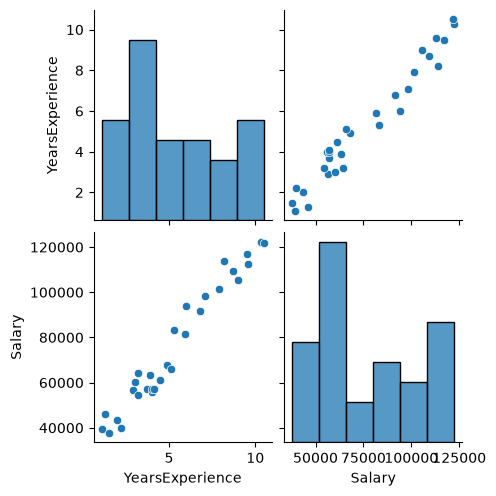

In [3]:
sns.pairplot(dataset)
plt.show()

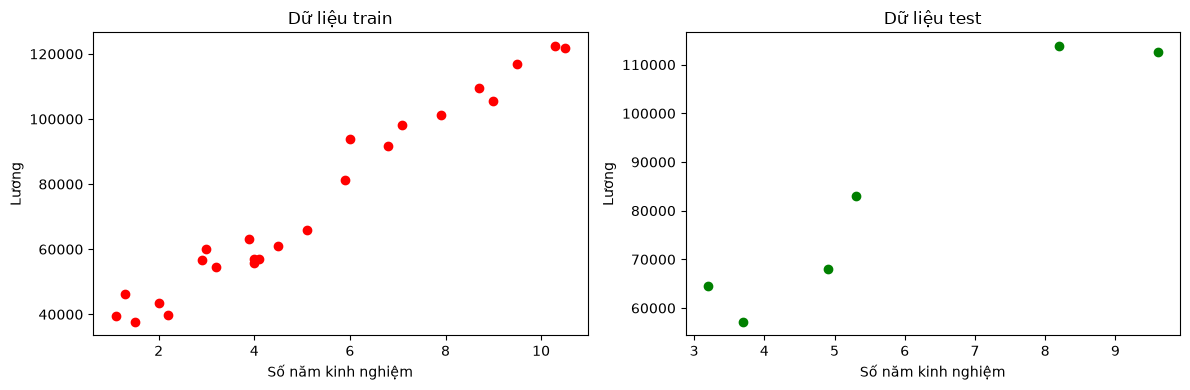

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X_train["YearsExperience"], y_train, color="red")
axes[0].set_title("Dữ liệu train")
axes[1].scatter(X_test["YearsExperience"], y_test, color="green")
axes[1].set_title("Dữ liệu test")
for ax in axes:
    ax.set_xlabel("Số năm kinh nghiệm")
    ax.set_ylabel("Lương")
fig.tight_layout()
plt.show()

## 3. Huấn luyện mô hình

`LinearRegression` ước lượng hệ số chặn $b_0$ và hệ số góc $b_1$ từ **tập train**. Chỉ dùng tập test để dự đoán và đánh giá.

In [5]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)
print(f"Salary = {regressor.intercept_:.2f} + {regressor.coef_[0]:.2f} × YearsExperience")

Salary = 25321.58 + 9423.82 × YearsExperience


### Dự đoán và đánh giá

Bảng sau giữ cùng thứ tự 6 dòng test; chỉ làm tròn giá trị hiển thị, còn R² tính trên dự đoán chưa làm tròn. `score()` của mô hình hồi quy là **R²**, không phải phần trăm dự đoán đúng.

In [6]:
y_pred = regressor.predict(X_test)
calculation = pd.DataFrame({
    "YearsExperience": X_test["YearsExperience"].to_numpy(),
    "Original Salary": y_test.to_numpy(),
    "Predict Salary": y_pred.round(1),
})
display(calculation)
print("Training R²:", regressor.score(X_train, y_train))
print("Testing R²:", regressor.score(X_test, y_test))

,YearsExperience,Original Salary,Predict Salary
0,9.6,112635.0,115790.2
1,4.9,67938.0,71498.3
2,8.2,113812.0,102596.9
3,5.3,83088.0,75267.8
4,3.2,64445.0,55477.8
5,3.7,57189.0,60189.7


Training R²: 0.9645401573418146
Testing R²: 0.9024461774180497


### Đường hồi quy trên tập train và test

Cùng một đường hồi quy đã học từ tập train được vẽ trên cả hai tập. Các điểm nằm trên tập test không tham gia huấn luyện.

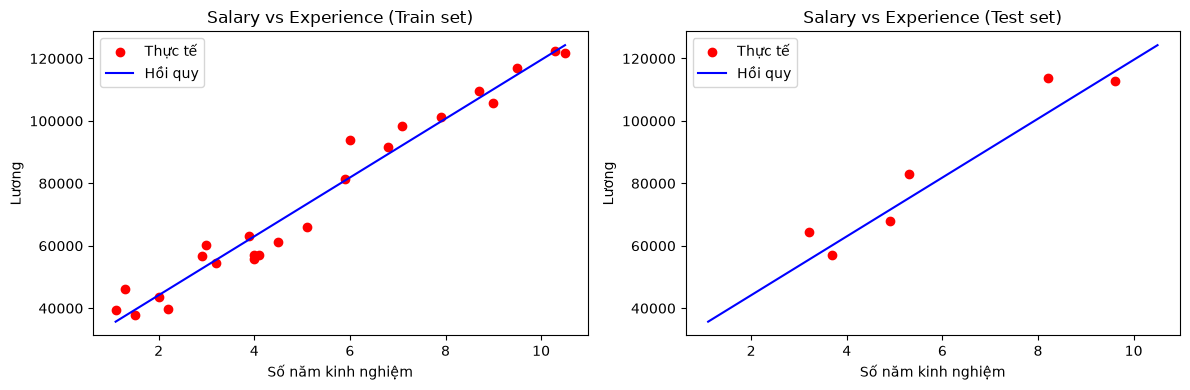

In [7]:
x_line = pd.DataFrame({"YearsExperience": sorted(X["YearsExperience"])})
y_line = regressor.predict(x_line)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, x_values, y_values, title in [
    (axes[0], X_train, y_train, "Salary vs Experience (Train set)"),
    (axes[1], X_test, y_test, "Salary vs Experience (Test set)"),
]:
    ax.scatter(x_values["YearsExperience"], y_values, color="red", label="Thực tế")
    ax.plot(x_line["YearsExperience"], y_line, color="blue", label="Hồi quy")
    ax.set(title=title, xlabel="Số năm kinh nghiệm", ylabel="Lương")
    ax.legend()
fig.tight_layout()
plt.show()

**Nhận xét:** Quan hệ giữa kinh nghiệm và lương trong bộ dữ liệu này gần tuyến tính. Với phép chia trong đề, R² train ≈ 0.96454 và R² test ≈ 0.90245; hiệu quả trên tập test thấp hơn train nhưng vẫn giải thích được phần lớn biến thiên lương trong 6 quan sát test.